This is a copy of the implementation done in 12, but in this implementation we will use a weight decay factor of 1e-4.

# Install Torchgeo

In [37]:
!uv pip install torchgeo

Using Python 3.13.15 environment at: /usr
Checked 1 package in 243ms


# Imports

In [38]:
import numpy as np
import gc

import torch
import torch.nn.functional as F
from torchgeo.models import ResNet18_Weights, resnet18
from torchgeo.trainers import SemanticSegmentationTask
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2

import lightning.pytorch as pl
from lightning.pytorch.loggers import TensorBoardLogger
from lightning.pytorch.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
)

import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
from pathlib import Path

# Load Google Drive for dataset

In [39]:
from google.colab import drive
drive.mount('/content/drive')
base_dir = "/content/drive/MyDrive/informal_settlement_segmentation"
data_dir = f"{base_dir}/data/deep_learning"
checkpoints_dir = f"{base_dir}/checkpoints/13"
logs_dir = f"{base_dir}/logs/13"
old_best_model_dir = f"{base_dir}/checkpoints/11/best.ckpt"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Setup Pytorch training and validation Datasets and Dataloaders with online augmentation functionality

In [40]:
def augment(image, mask):
    import random

    # flip horizontally with 50% chance
    if random.random() < 0.5:
        image = torch.flip(image, dims=[-1])
        mask = torch.flip(mask, dims=[-1])

    # flip vertically with 50% chance
    if random.random() < 0.5:
        image = torch.flip(image, dims=[-2])
        mask = torch.flip(mask, dims=[-2])

    # rotate 0, 90, 180, or 270 degree rotation each with 25% chance
    k = random.randint(0, 3)

    image = torch.rot90(image, k=k, dims=(-2, -1))
    mask = torch.rot90(mask, k=k, dims=(-2, -1))

    return image, mask

class TorchDataset(Dataset):
    def __init__(self, patches, apply_augmentation):
        self.patches = patches
        self.apply_augmentation = apply_augmentation

    def __len__(self): return len(self.patches)
    def __getitem__(self, idx):
        patch = torch.from_numpy(self.patches[idx])

        if self.apply_augmentation:
            image = patch[:-1]
            mask = patch[-1:]
            image, mask = augment(image, mask)
            patch = torch.cat([image, mask], dim=0)

        return patch

train_dataset = TorchDataset(np.load(data_dir + "/train_patches.npy"), apply_augmentation = True)
val_dataset = TorchDataset(np.load(data_dir + "/val_patches.npy"), apply_augmentation = False)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    pin_memory=True,
    num_workers=2,
    persistent_workers=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    pin_memory=True,
    num_workers=2,
    persistent_workers=True,
)

# Load and inspect Torchgeo's resnet18 model pretrained on Sentinel-2 imagery

In [41]:
weights = ResNet18_Weights.SENTINEL2_ALL_MOCO
print('Weight metadata:')
for key, value in weights.meta.items(): print(f' {key}: {value}')

Weight metadata:
 dataset: SSL4EO-S12
 in_chans: 13
 model: resnet18
 publication: https://arxiv.org/abs/2211.07044
 repo: https://github.com/zhu-xlab/SSL4EO-S12
 ssl_method: moco
 bands: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8a', 'B9', 'B10', 'B11', 'B12']


# Override segmentation task to use AdamW optimizer (decay strength = 1e-5) and add batch upscaling

In [42]:
class CustomSegmentationTask(SemanticSegmentationTask):
    def configure_optimizers(self):
        optimizer = torch.optim.AdamW(
            self.parameters(),
            lr=self.hparams.lr,
            weight_decay=5e-5,
        )

        return optimizer

    def on_after_batch_transfer(self, batch, dataloader_idx=0):

        batch = F.interpolate(batch, size=(224, 224), mode="nearest")

        images = batch[:, :-1]
        masks  = batch[:, -1]

        return {"image": images, "mask": masks}

# Stage 1 training

# Load and use experiment 11's best model

In [43]:
task = CustomSegmentationTask(
    model="unet",
    backbone="resnet18",
    weights=weights,
    in_channels=13,
    task="binary",
    loss="jaccard",
    lr=1e-4,
    freeze_backbone=False,
)

checkpoint = torch.load(old_best_model_dir, map_location="cpu")
task.load_state_dict(checkpoint["state_dict"])

print(task.model)

Unet(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(13, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, trac

In [44]:
# Call configure_optimizers to inspect the setup
opt_config = task.configure_optimizers()

# Extract and print the optimizer instance
optimizer = opt_config["optimizer"] if isinstance(opt_config, dict) else opt_config
print(optimizer)

AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 5e-05
)


# Check parameter distribution

In [45]:
encoder_params = sum(p.numel() for p in task.model.encoder.parameters())
decoder_params = sum(p.numel() for p in task.model.decoder.parameters())
head_params = sum(p.numel() for p in task.model.segmentation_head.parameters())

total_params = encoder_params + decoder_params + head_params

print(f"Encoder:     {encoder_params:,}")
print(f"Decoder:     {decoder_params:,}")
print(f"Head:        {head_params:,}")
print(f"Total:       {total_params:,}")

Encoder:     11,207,872
Decoder:     3,151,552
Head:        145
Total:       14,359,569


# Add checkpointing and early stopping functionality

In [46]:
phase2_best = ModelCheckpoint(
    dirpath=checkpoints_dir,
    filename="best",
    monitor="val_loss",
    mode="min",
    save_top_k=1,
    save_last=True,
)

phase2_periodic = ModelCheckpoint(
    dirpath=checkpoints_dir,
    filename="epoch-{epoch:03d}",
    every_n_epochs=5,
    save_top_k=-1,
)

phase2_early_stop = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=10,
    verbose=True,
)

# Create trainer and logger using Pytorch Lightning

In [47]:
logger_stage2 = TensorBoardLogger(
    save_dir=logs_dir,
    name="results",
)

trainer_stage2 = pl.Trainer(
    accelerator="gpu",
    devices=1,
    precision="16-mixed",
    max_epochs=100,
    logger=logger_stage2,
    callbacks=[
        phase2_best,
        phase2_periodic,
        phase2_early_stop,
    ],

    log_every_n_steps=1,
)

INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [48]:
trainer_stage2.fit(
    task,
    train_dataloaders=train_loader,
    val_dataloaders=val_loader,
)

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory /content/drive/MyDrive/informal_settlement_segmentation/checkpoints/13 exists and is not empty.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name          ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model         │ Unet             │ 14.4 M │ train │     0 │
│ 1 │ criterion     │ JaccardLoss      │      0 │ train │     0 │
│ 2 │ train_metrics │ MetricCollection │      0 │ train │     0 │
│ 3 │ val_metrics   │ MetricCollection │      0 │ train │     0 │
│ 4 │ test_metrics  │ MetricCollection │      0 │ train │     0 │
└───┴───────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 14.4 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 14.4 M                                                                                               
Total estimated model params size (MB): 57.438                                                                     
Modules in train mode: 174                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO: Metric val_loss improved. New best score: 0.538
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_loss improved. New best score: 0.538
INFO: Metric val_loss improved by 0.032 >= min_delta = 0.0. New best score: 0.507
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_loss improved by 0.032 >= min_delta = 0.0. New best score: 0.507
INFO: Metric val_loss improved by 0.000 >= min_delta = 0.0. New best score: 0.506
INFO:lightning.pytorch.callbacks.early_stopping:Metric val_loss improved by 0.000 >= min_delta = 0.0. New best score: 0.506
INFO: Monitored metric val_loss did not improve in the last 10 records. Best score: 0.506. Signaling Trainer to stop.
INFO:lightning.pytorch.callbacks.early_stopping:Monitored metric val_loss did not improve in the last 10 records. Best score: 0.506. Signaling Trainer to stop.


In [49]:
event_file = next(p for p in Path(logger_stage2.log_dir).glob("events.out.tfevents.*"))

ea = EventAccumulator(str(event_file))
ea.Reload()

for metric in ["train_loss", "val_loss",]:
    events = ea.Scalars(metric)

    print(
        metric,
        "points:", len(events),
        "first step:", events[0].step,
        "last step:", events[-1].step,
    )

train_loss points: 1782 first step: 0 last step: 1781
val_loss points: 18 first step: 98 last step: 1781


In [50]:
train_losses = [x.value for x in ea.Scalars("train_loss")]
val_losses = [x.value for x in ea.Scalars("val_loss")]

In [51]:
train_losses_np = np.array(train_losses)

num_epochs = len(val_losses)
steps_per_epoch = len(train_losses_np) // num_epochs

# Reshape: rows = epochs, columns = batches within each epoch
epoch_losses = train_losses_np.reshape(num_epochs, steps_per_epoch)

# Average batch losses within each epoch
train_loss_per_epoch = epoch_losses.mean(axis=1)
train_loss_per_epoch.shape

(18,)

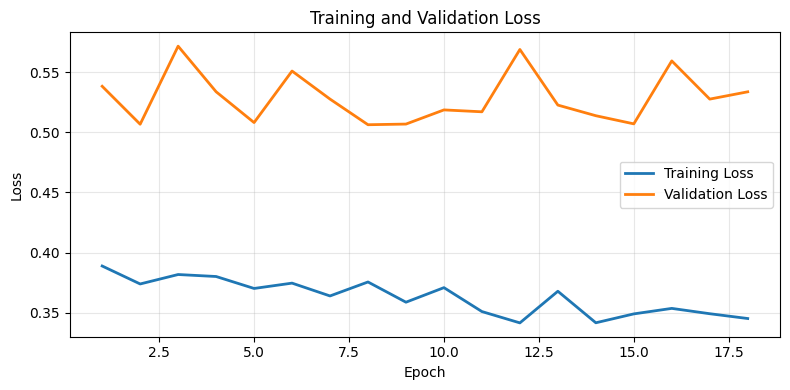

In [52]:
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 4))

plt.plot(epochs, train_loss_per_epoch, label="Training Loss", linewidth=2)
plt.plot(epochs, val_losses, label="Validation Loss", linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [53]:
train_jaccard_scores = [x.value for x in ea.Scalars("train_AverageJaccardIndex")]
val_jaccard_scores = [x.value for x in ea.Scalars("val_AverageJaccardIndex")]

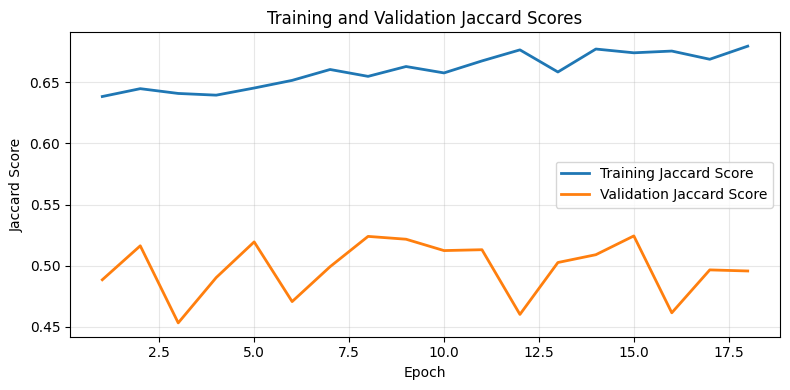

In [54]:
plt.figure(figsize=(8, 4))

plt.plot(epochs, train_jaccard_scores, label="Training Jaccard Score", linewidth=2)
plt.plot(epochs, val_jaccard_scores, label="Validation Jaccard Score", linewidth=2)

plt.xlabel("Epoch")
plt.ylabel("Jaccard Score")
plt.title("Training and Validation Jaccard Scores")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Analysis

Increasing the weight decay from `1e-5` to `5e-5` did not have a significant effect on the model's performance. The training loss continued to decrease slowly, while the validation loss remained relatively stable and fluctuated within a similar range to the previous experiment. This suggests that increasing the regularization strength did not provide a meaningful improvement in the model's generalization.

Considering the results of the previous experiments, further tuning of weight decay is unlikely to provide substantial benefits without additional evidence that a different value would improve validation performance. Therefore, rather than continuing to make increasingly small changes to the model's hyperparameters, the next stage will focus on optimizing the probability threshold used to produce the final binary segmentation masks.